# Serie II: revisión de archivos y EDA de la caldera

La primera parte compara `data.csv` con `data_AutoReg.csv`. El resto explora `data.csv`, que conserva los faltantes originales. El artículo de la fuente describe la segunda versión como completada mediante AutoReg; esta revisión conserva ambas como versiones del mismo historial y no las concatena. [Artículo de datos, Scientific Data](https://doi.org/10.1038/s41597-025-05096-4).

In [1]:
from pathlib import Path
import pandas as pd

candidatos = [Path("data/raw/serie2"), Path("../data/raw/serie2")]
ruta = next((p for p in candidatos if (p / "data.csv").exists()), None)
if ruta is None:
    raise FileNotFoundError(
        "No encuentro los archivos de Serie II. Descarga data.csv y data_AutoReg.csv "
        "desde el enlace del dataset indicado en el PDF y guárdalos en data/raw/serie2/."
    )

ruta_original = ruta / "data.csv"
ruta_completada = ruta / "data_AutoReg.csv"
original = pd.read_csv(ruta_original, low_memory=False)
completada = pd.read_csv(ruta_completada, low_memory=False)
objetivo = "YJJWSLL.AV_0#"  # Flujo de salida del agua de atemperación primaria
print("data.csv:", original.shape)
print("data_AutoReg.csv:", completada.shape)

data.csv: (86400, 31)
data_AutoReg.csv: (86400, 31)


## Comparación de estructura y tiempo

Primero se comprueba que ambos archivos describan las mismas filas en el mismo orden. Después se compara cada columna para localizar cualquier cambio.

In [2]:
resumen_estructura = pd.DataFrame(
    {
        "comprobación": ["Mismas columnas y orden", "Mismas filas", "Mismas marcas de tiempo y orden"],
        "resultado": [
            original.columns.equals(completada.columns),
            len(original) == len(completada),
            original["date"].equals(completada["date"]),
        ],
    }
)
assert resumen_estructura["resultado"].all()
resumen_estructura

,comprobación,resultado
0,Mismas columnas y orden,True
1,Mismas filas,True
2,Mismas marcas de tiempo y orden,True


## Diferencias entre las mediciones

Se cuentan las celdas que cambian por sensor. Para confirmar una imputación, los valores originales disponibles deben coincidir con los de la versión completada, y toda ausencia original debe tener ahora un valor finito.

In [3]:
diferencias = {}
for columna in original.columns:
    if columna == "date":
        continue
    iguales = original[columna].eq(completada[columna]) | (
        original[columna].isna() & completada[columna].isna()
    )
    diferencias[columna] = int((~iguales).sum())

resumen_diferencias = (
    pd.Series(diferencias, name="celdas_distintas")
    .loc[lambda s: s.ne(0)]
    .sort_values(ascending=False)
    .to_frame()
)
resumen_diferencias

,celdas_distintas
YJJWSLL.AV_0#,30


In [4]:
faltantes_original = original[objetivo].isna()
coinciden_o_faltan_en_origen = original[objetivo].eq(completada[objetivo]) | faltantes_original

assert resumen_diferencias.index.tolist() == [objetivo]
assert int((~coinciden_o_faltan_en_origen).sum()) == 0
assert int(faltantes_original.sum()) == int(resumen_diferencias.loc[objetivo, "celdas_distintas"])
assert original.loc[~faltantes_original, objetivo].equals(
    completada.loc[~faltantes_original, objetivo]
)
assert completada.loc[faltantes_original, objetivo].notna().all()

pd.DataFrame(
    {
        "medición": [objetivo],
        "faltantes_en_data_csv": [int(faltantes_original.sum())],
        "faltantes_en_data_AutoReg": [int(completada[objetivo].isna().sum())],
        "valores_originales_preservados": [int((~faltantes_original).sum())],
        "valores_rellenados": [int(faltantes_original.sum())],
    }
)

,medición,faltantes_en_data_csv,faltantes_en_data_AutoReg,valores_originales_preservados,valores_rellenados
0,YJJWSLL.AV_0#,30,0,86370,30


## En qué momentos se completaron valores

Se agrupan faltantes consecutivos en tramos para distinguir una interrupción de una sucesión de puntos ausentes. La duración se expresa según la marca de tiempo observada, con intervalos de cinco segundos.

In [5]:
fechas = pd.to_datetime(original["date"], errors="raise")
indices = original.index[faltantes_original].to_list()
tramos = []
if indices:
    inicio = anterior = indices[0]
    for indice in indices[1:]:
        if indice != anterior + 1:
            tramos.append((inicio, anterior))
            inicio = indice
        anterior = indice
    tramos.append((inicio, anterior))

filas = []
for inicio, fin in tramos:
    filas.append(
        {
            "inicio": fechas.iloc[inicio],
            "fin": fechas.iloc[fin],
            "mediciones_ausentes": fin - inicio + 1,
        }
    )
pd.DataFrame(filas)

,inicio,fin,mediciones_ausentes
0,2022-03-28 06:22:24,2022-03-28 06:24:39,28
1,2022-03-30 05:54:44,2022-03-30 05:54:49,2


## Resultado de esta verificación

Los archivos tienen que conservarse como dos versiones del mismo registro temporal, no como dos muestras para concatenar. Para análisis que requieran la señal observada, la base es `data.csv`; cuando se evalúe una versión imputada, debe identificarse como tal y compararse como escenario de sensibilidad. Los valores AutoReg no son nuevas observaciones del sensor.

## Qué mide cada columna

`columns.csv` da el nombre del atributo, pero no proporciona unidades ni rangos operativos permitidos. La traducción de abajo ayuda a leer las señales; mantengo el código original porque identifica el punto del sistema.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

sensores = original.columns.drop("date").tolist()
diccionario = pd.read_csv(ruta / "columns.csv")
diccionario["columna"] = diccionario["Variant"].astype(str) + "#"

significado_es = {
    "PT_8313A.AV_0#": "Presión en la parte superior del hogar, punto A",
    "PT_8313B.AV_0#": "Presión en la parte superior del hogar, punto B",
    "PT_8313C.AV_0#": "Presión en la parte superior del hogar, punto C",
    "PT_8313D.AV_0#": "Presión en la parte superior del hogar, punto D",
    "PT_8313E.AV_0#": "Presión en la parte superior del hogar, punto E",
    "PT_8313F.AV_0#": "Presión en la parte superior del hogar, punto F",
    "PTCA_8322A.AV_0#": "Presión del recipiente de caldera, lado izquierdo",
    "PTCA_8324.AV_0#": "Presión de vapor a la salida del recipiente",
    "TE_8319A.AV_0#": "Temperatura de gases a la salida superior del economizador, lado izquierdo",
    "TE_8319B.AV_0#": "Temperatura de gases a la salida superior del economizador, lado derecho",
    "TE_8313B.AV_0#": "Temperatura en la parte superior de la cámara del hogar, lado derecho",
    "TE_8303.AV_0#": "Temperatura del aire primario al salir del precalentador",
    "TE_8304.AV_0#": "Temperatura del aire secundario al salir del precalentador",
    "TE_8332A.AV_0#": "Temperatura del vapor a la salida de la caldera",
    "TV_8329ZC.AV_0#": "Señal de la válvula reguladora del vapor del atemperador primario",
    "FT_8301.AV_0#": "Caudal a la salida del ventilador primario",
    "FT_8302.AV_0#": "Caudal a la salida del ventilador secundario",
    "FT_8306A.AV_0#": "Caudal de aire de la cámara de retorno, lado izquierdo",
    "FT_8306B.AV_0#": "Caudal de aire de la cámara de retorno, lado derecho",
    "AIR_8301A.AV_0#": "Oxígeno en gases a la entrada superior del economizador, lado izquierdo",
    "AIR_8301B.AV_0#": "Oxígeno en gases a la entrada superior del economizador, lado derecho",
    "YFJ3_AI.AV_0#": "Corriente del motor del ventilador de tiro inducido",
    "YFJ3_ZD1.AV_0#": "Vibración del soporte del cojinete del ventilador de tiro inducido, punto A",
    "YFJ3_ZD2.AV_0#": "Vibración del soporte del cojinete del ventilador de tiro inducido, punto B",
    "SXLTCYZ.AV_0#": "Presión diferencial entre zonas alta y baja del hogar, lado izquierdo",
    "SXLTCYY.AV_0#": "Presión diferencial entre zonas alta y baja del hogar, lado derecho",
    "ZCLCCY.AV_0#": "Presión diferencial de la capa izquierda",
    "YCLCCY.AV_0#": "Presión diferencial de la capa derecha",
    "YJJWSLL.AV_0#": "Caudal de agua de atemperación primaria",
    "ZZQBCHLL.AV_0#": "Caudal de vapor principal después de compensación",
}
assert set(diccionario["columna"]) == set(sensores)
assert set(significado_es) == set(sensores)
catalogo = diccionario.set_index("columna").loc[sensores].reset_index()
catalogo["significado_es"] = catalogo["columna"].map(significado_es)
catalogo[["columna", "Attribute name", "significado_es"]]

,columna,Attribute name,significado_es
0,PT_8313A.AV_0#,Upper furnace pressure (A),"Presión en la parte superior del hogar, punto A"
1,PT_8313B.AV_0#,Upper furnace pressure (B),"Presión en la parte superior del hogar, punto B"
2,PT_8313C.AV_0#,Upper furnace pressure (C),"Presión en la parte superior del hogar, punto C"
3,PT_8313D.AV_0#,Upper furnace pressure (D),"Presión en la parte superior del hogar, punto D"
4,PT_8313E.AV_0#,Upper furnace pressure (E),"Presión en la parte superior del hogar, punto E"
5,PT_8313F.AV_0#,Upper furnace pressure (F),"Presión en la parte superior del hogar, punto F"
6,PTCA_8322A.AV_0#,Pot pressure (left),"Presión del recipiente de caldera, lado izquierdo"
7,PTCA_8324.AV_0#,Container outlet vapour pressure,Presión de vapor a la salida del recipiente
8,TE_8319A.AV_0#,Flue gas temperature at the upper economizer o...,Temperatura de gases a la salida superior del ...
9,TE_8319B.AV_0#,Flue gas temperature at the upper economizer o...,Temperatura de gases a la salida superior del ...


## Cobertura temporal, tipos y faltantes

Cada fila debería representar un instante, por lo que `date` es la llave natural para revisar repetidos y continuidad. Los sensores son señales simultáneas; una fecha no se debe tratar como una unidad independiente para entrenar modelos al azar.

In [7]:
datos = original.copy()
datos["date"] = pd.to_datetime(datos["date"], errors="coerce")
valores = datos[sensores]
intervalos = datos["date"].diff().dt.total_seconds().dropna()
resumen_general = pd.DataFrame(
    {
        "medida": [
            "Filas", "Sensores", "Fechas inválidas", "Fechas únicas",
            "Fechas en orden original", "Primer instante", "Último instante",
            "Intervalos de 5 segundos", "Intervalos distintos de 5 segundos",
            "Filas con algún faltante", "Celdas de sensor faltantes", "Celdas infinitas",
        ],
        "resultado": [
            len(datos), len(sensores), int(datos["date"].isna().sum()),
            int(datos["date"].nunique()), bool(datos["date"].is_monotonic_increasing),
            str(datos["date"].min()), str(datos["date"].max()),
            int(intervalos.eq(5).sum()), int(intervalos.ne(5).sum()),
            int(valores.isna().any(axis=1).sum()), int(valores.isna().sum().sum()),
            int(np.isinf(valores.to_numpy()).sum()),
        ],
    }
)
resumen_general

,medida,resultado
0,Filas,86400
1,Sensores,30
2,Fechas inválidas,0
3,Fechas únicas,86400
4,Fechas en orden original,True
5,Primer instante,2022-03-27 14:28:54
6,Último instante,2022-04-01 14:28:49
7,Intervalos de 5 segundos,86399
8,Intervalos distintos de 5 segundos,0
9,Filas con algún faltante,30


## Significado físico y disponibilidad para el sensor virtual

La fuente describe una caldera de carbón con adquisición DCS. Se distinguen circuito de combustión/aire/gases, condiciones de presión y temperatura del agua/vapor, atemperación y estado del ventilador. El análisis completo por familia, ambigüedades y fuentes está en [significado físico y disponibilidad](../docs/serie2-significado-disponibilidad.md).

**Alcance propuesto:** estimar `ZZQBCHLL(t)` con otras señales recibidas hasta `t`, sin usar el propio caudal ni sus rezagos como entradas para el escenario de reemplazo de un caudalímetro indisponible. No es un pronóstico de un horizonte futuro. Hay 29 candidatas históricas, pero el CSV no incluye fecha de recepción, latencia ni calidad: su uso contemporáneo queda condicionado a que estén disponibles al emitir la estimación. No se confirma independencia frente a fallas compartidas de adquisición.

La tabla conserva la descripción original y cuantifica cobertura y retención por pares. Que una lectura se repita no demuestra falta de disponibilidad ni avería. Solo `TE_8332A` tiene unidad °C confirmada expresamente en la fuente consultada; no se asignan porcentajes a válvula/oxígeno ni toneladas por hora al vapor por su apariencia numérica.


In [8]:
disponibilidad_sensores = catalogo[["columna", "Attribute name", "significado_es"]].copy().set_index("columna")
disponibilidad_sensores["registros_validos"] = valores.notna().sum()
disponibilidad_sensores["faltantes"] = valores.isna().sum()
disponibilidad_sensores["cobertura_pct"] = 100 * valores.notna().mean()
disponibilidad_sensores["unidad_confirmada"] = "No documentada por tag"
disponibilidad_sensores.loc["TE_8332A.AV_0#", "unidad_confirmada"] = "°C"
disponibilidad_sensores["papel_propuesto"] = "Candidata; disponibilidad en línea condicionada"
disponibilidad_sensores.loc["ZZQBCHLL.AV_0#", "papel_propuesto"] = "Objetivo; excluir de entradas y rezagos en escenario de reemplazo"
# Pares anclados en la primera fila; se comparan solo pares completos.
iguales_por_par = {}
for sensor in sensores:
    primera = valores[sensor].iloc[::2].reset_index(drop=True)
    segunda = valores[sensor].iloc[1::2].reset_index(drop=True)
    par_valido = primera.notna() & segunda.notna()
    iguales_por_par[sensor] = 100 * primera[par_valido].eq(segunda[par_valido]).mean()
disponibilidad_sensores["pares_con_lectura_igual_pct"] = pd.Series(iguales_por_par)
display(disponibilidad_sensores.round(5))


,Attribute name,significado_es,registros_validos,faltantes,cobertura_pct,unidad_confirmada,papel_propuesto,pares_con_lectura_igual_pct
columna,,,,,,,,
PT_8313A.AV_0#,Upper furnace pressure (A),"Presión en la parte superior del hogar, punto A",86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,0.34954
PT_8313B.AV_0#,Upper furnace pressure (B),"Presión en la parte superior del hogar, punto B",86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,0.55093
PT_8313C.AV_0#,Upper furnace pressure (C),"Presión en la parte superior del hogar, punto C",86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,0.58333
PT_8313D.AV_0#,Upper furnace pressure (D),"Presión en la parte superior del hogar, punto D",86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,0.40278
PT_8313E.AV_0#,Upper furnace pressure (E),"Presión en la parte superior del hogar, punto E",86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,0.52778
PT_8313F.AV_0#,Upper furnace pressure (F),"Presión en la parte superior del hogar, punto F",86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,0.60417
PTCA_8322A.AV_0#,Pot pressure (left),"Presión del recipiente de caldera, lado izquierdo",86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,79.04861
PTCA_8324.AV_0#,Container outlet vapour pressure,Presión de vapor a la salida del recipiente,86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,78.17593
TE_8319A.AV_0#,Flue gas temperature at the upper economizer o...,Temperatura de gases a la salida superior del ...,86400,0,100.00000,No documentada por tag,Candidata; disponibilidad en línea condicionada,43.99769


**Decisión provisional:** conservar las 29 candidatas. De ellas, 28 no tienen faltantes y el agua de atemperación tiene 30 (0.03472 %). Cuatro predictoras de presión diferencial y el objetivo repiten todos los pares, compatible con actualización efectiva de diez segundos o retención; no se demuestra la causa. El análisis de retardos sigue pendiente.

La válvula no se identifica inequívocamente como consigna o posición real; el agua de atemperación no es agua total de alimentación. Los nombres `pot`, `container` y `layer` tampoco justifican identificar un componente exacto sin plano. La corriente no es potencia eléctrica y la vibración no tiene umbral mecánico interpretable sin unidad/banda.

El objetivo está compensado, pero no se conoce su fórmula: revisar si algún predictor comparte el caudalímetro o una señal calculada a partir del propio objetivo. Que presión o temperatura entren en una compensación no basta para declarar fuga de información; importan la dependencia del instrumento averiado y la disponibilidad real. No usar datos futuros para rellenar faltantes; cualquier ajuste y selección se realizará dentro del entrenamiento. La documentación física permite plantear asociaciones, no demostrar causalidad ni optimizar controles con este EDA.


## Duplicados

Compruebo tres casos: fila completa repetida, marca de tiempo repetida y vector de 30 lecturas idéntico aunque cambie la fecha. También mido las repeticiones consecutivas de cada señal: un sensor puede mantener legítimamente el mismo valor y eso no duplica la fila.

In [9]:
resumen_duplicados = pd.DataFrame(
    {
        "comprobación": [
            "Filas completas repetidas",
            "Marcas de tiempo repetidas",
            "Vectores de sensores repetidos sin considerar fecha",
        ],
        "cantidad": [
            int(datos.duplicated().sum()),
            int(datos["date"].duplicated().sum()),
            int(valores.duplicated().sum()),
        ],
    }
)
resumen_duplicados

,comprobación,cantidad
0,Filas completas repetidas,0
1,Marcas de tiempo repetidas,0
2,Vectores de sensores repetidos sin considerar ...,0


## Resumen estadístico y candidatos a revisar

Los límites de Tukey (1.5 rangos intercuartílicos) y el puntaje robusto con MAD (`|z| > 3.5`) sirven para señalar valores alejados de la distribución global. En una serie con cambios de carga y dependencia temporal, pueden marcar estados legítimos. Sin unidades ni límites del fabricante, estos conteos no clasifican fallas.

In [10]:
resumen = []
outliers = []
repeticiones = []
for sensor in sensores:
    s = valores[sensor]
    validos = s.dropna()
    q01, q25, mediana, q75, q99 = validos.quantile([0.01, 0.25, 0.50, 0.75, 0.99])
    q1, q3 = q25, q75
    iqr = q3 - q1
    fuera_iqr = (validos < q1 - 1.5 * iqr) | (validos > q3 + 1.5 * iqr)
    mad = (validos - mediana).abs().median()
    z_robusto = 0.67448975 * (validos - mediana) / mad if mad > 0 else pd.Series(0.0, index=validos.index)
    fuera_mad = z_robusto.abs() > 3.5

    pares_validos = s.notna() & s.shift().notna()
    iguales_adyacentes = s.eq(s.shift()) & pares_validos
    grupos = (~iguales_adyacentes).cumsum()
    tamanos = s.groupby(grupos).size()
    grupo_largo = tamanos.idxmax()
    indices_largo = s.index[grupos.eq(grupo_largo)]
    largo = int(len(indices_largo))
    inicio, fin = datos.loc[indices_largo[0], "date"], datos.loc[indices_largo[-1], "date"]

    resumen.append({
        "sensor": sensor,
        "tipo": str(s.dtype),
        "faltantes": int(s.isna().sum()),
        "negativos": int(s.lt(0).sum()),
        "ceros": int(s.eq(0).sum()),
        "valores_distintos": int(validos.nunique()),
        "mínimo": validos.min(),
        "p01": q01,
        "mediana": mediana,
        "p99": q99,
        "máximo": validos.max(),
        "pares_adyacentes_iguales_pct": 100 * iguales_adyacentes.sum() / max(pares_validos.sum(), 1),
        "tramo_igual_máximo_muestras": largo,
    })
    outliers.append({
        "sensor": sensor,
        "candidatos_Tukey": int(fuera_iqr.sum()),
        "pct_Tukey": 100 * fuera_iqr.mean(),
        "candidatos_MAD_3_5": int(fuera_mad.sum()),
        "pct_MAD_3_5": 100 * fuera_mad.mean(),
    })
    repeticiones.append({
        "sensor": sensor,
        "máximo_muestras_iguales": largo,
        "inicio": inicio,
        "fin": fin,
        "minutos_transcurridos": max(largo - 1, 0) * 5 / 60,
        "valor": s.loc[indices_largo[0]],
    })

tabla_resumen_sensores = pd.DataFrame(resumen).set_index("sensor")
tabla_candidatos = pd.DataFrame(outliers).set_index("sensor")
tabla_repeticiones = pd.DataFrame(repeticiones).set_index("sensor")
tabla_resumen_sensores.head()

,tipo,faltantes,negativos,ceros,valores_distintos,mínimo,p01,mediana,p99,máximo,pares_adyacentes_iguales_pct,tramo_igual_máximo_muestras
sensor,,,,,,,,,,,,
PT_8313A.AV_0#,float64,0,86263,0,4132,-484.70,-292.9300,-135.32,-24.9600,75.33,0.351856,3
PT_8313B.AV_0#,float64,0,86388,0,4038,-549.57,-335.3934,-186.76,-78.1592,51.83,0.481487,3
PT_8313C.AV_0#,float64,0,86370,0,3826,-509.12,-287.2200,-151.43,-49.6300,126.28,0.578710,3
PT_8313D.AV_0#,float64,0,86068,0,3874,-501.23,-250.7100,-116.52,-12.8700,256.53,0.422459,2
PT_8313E.AV_0#,float64,0,86351,0,4145,-586.83,-310.6408,-165.36,-53.2400,245.11,0.513895,3


In [11]:
tabla_candidatos.sort_values(
    ["candidatos_MAD_3_5", "candidatos_Tukey"], ascending=False
).round(3)

,candidatos_Tukey,pct_Tukey,candidatos_MAD_3_5,pct_MAD_3_5
sensor,,,,
PTCA_8324.AV_0#,3352,3.880,1832,2.120
AIR_8301A.AV_0#,2970,3.438,1604,1.856
AIR_8301B.AV_0#,2933,3.395,1265,1.464
YFJ3_ZD2.AV_0#,2175,2.517,1084,1.255
YFJ3_AI.AV_0#,1951,2.258,942,1.090
PTCA_8322A.AV_0#,2600,3.009,609,0.705
PT_8313A.AV_0#,1208,1.398,562,0.650
SXLTCYZ.AV_0#,1164,1.347,554,0.641
PT_8313B.AV_0#,1156,1.338,547,0.633


### Ejemplos extremos para revisión contextual

La tabla muestra el valor con mayor desviación robusta global de cada sensor que supera `|z| > 3.5`, ordenados por magnitud. Son marcas para inspección temporal; no se eliminan ni se les asigna causa con este EDA.

In [12]:
ejemplos_extremos = []
for sensor in sensores:
    s = valores[sensor]
    validos = s.dropna()
    mediana = validos.median()
    mad = (validos - mediana).abs().median()
    if mad == 0:
        continue
    puntaje = 0.67448975 * (s - mediana) / mad
    indice = puntaje.abs().idxmax()
    if abs(puntaje.loc[indice]) > 3.5:
        ejemplos_extremos.append({
            "sensor": sensor,
            "fecha": datos.loc[indice, "date"],
            "lectura": s.loc[indice],
            "mediana_global": mediana,
            "z_robusto": puntaje.loc[indice],
        })
pd.DataFrame(ejemplos_extremos).assign(
    abs_z=lambda tabla: tabla["z_robusto"].abs()
).sort_values("abs_z", ascending=False).head(12).drop(columns="abs_z").round(3)

C:\Users\user\AppData\Local\Temp\ipykernel_4832\3570077255.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).sort_values("abs_z", ascending=False).head(12).drop(columns="abs_z").round(3)


,sensor,fecha,lectura,mediana_global,z_robusto
17,YFJ3_AI.AV_0#,2022-03-29 14:06:59,51.28,22.66,35.748
13,FT_8306A.AV_0#,2022-03-30 08:53:09,262.49,708.56,-15.226
15,FT_8306B.AV_0#,2022-03-30 08:53:09,304.96,614.19,-12.749
19,YFJ3_ZD2.AV_0#,2022-03-30 07:47:09,24.96,6.35,11.011
14,AIR_8301A.AV_0#,2022-03-28 19:25:49,4.56,2.07,9.330
16,AIR_8301B.AV_0#,2022-03-28 19:25:49,5.05,2.20,8.738
4,PT_8313E.AV_0#,2022-03-28 14:08:09,-586.83,-165.36,-7.786
3,PT_8313D.AV_0#,2022-03-28 14:08:24,-501.23,-116.52,-7.709
5,PT_8313F.AV_0#,2022-03-28 14:08:09,-562.75,-154.96,-7.623
2,PT_8313C.AV_0#,2022-03-28 14:08:24,-509.12,-151.43,-7.333


### Candidatos que coinciden en el tiempo

Para ver si los valores extremos aparecen aislados o junto con otras señales, cuento en cada fecha cuántos sensores superan el umbral MAD global. Los episodios con tres o más señales son una exploración visual y no una regla de alarma.

In [13]:
banderas_mad = pd.DataFrame(index=datos.index)
for sensor in sensores:
    s = valores[sensor]
    validos = s.dropna()
    mediana = validos.median()
    mad = (validos - mediana).abs().median()
    puntaje = 0.67448975 * (s - mediana) / mad if mad > 0 else pd.Series(0.0, index=s.index)
    banderas_mad[sensor] = puntaje.abs() > 3.5

cantidad_banderas = banderas_mad.sum(axis=1)
episodio = cantidad_banderas.ge(3)
grupo = (episodio != episodio.shift(fill_value=False)).cumsum()
filas_episodios = []
for id_grupo in grupo.loc[episodio].unique():
    indices = datos.index[grupo.eq(id_grupo)]
    pico = cantidad_banderas.loc[indices].idxmax()
    filas_episodios.append({
        "inicio": datos.loc[indices[0], "date"],
        "fin": datos.loc[indices[-1], "date"],
        "muestras": len(indices),
        "máximo_sensores_señalados": int(cantidad_banderas.loc[pico]),
        "sensores_en_pico": ", ".join(banderas_mad.columns[banderas_mad.loc[pico]]),
    })

tabla_episodios = pd.DataFrame(filas_episodios)
resumen_coincidencia = pd.DataFrame({
    "medida": [
        "Filas con al menos un candidato MAD",
        "Filas con tres o más sensores señalados",
        "Episodios contiguos con tres o más sensores señalados",
    ],
    "resultado": [
        int(cantidad_banderas.ge(1).sum()),
        int(episodio.sum()),
        len(tabla_episodios),
    ],
})
resumen_coincidencia

,medida,resultado
0,Filas con al menos un candidato MAD,6817
1,Filas con tres o más sensores señalados,899
2,Episodios contiguos con tres o más sensores se...,132


In [14]:
tabla_episodios.sort_values(
    ["muestras", "máximo_sensores_señalados"], ascending=False
).head(10).reset_index(drop=True)

,inicio,fin,muestras,máximo_sensores_señalados,sensores_en_pico
0,2022-03-31 16:27:54,2022-03-31 16:37:29,116,7,"TE_8313B.AV_0#, TV_8329ZC.AV_0#, FT_8302.AV_0#..."
1,2022-03-31 11:50:34,2022-03-31 11:59:04,103,11,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."
2,2022-04-01 10:10:04,2022-04-01 10:12:39,32,5,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."
3,2022-03-29 21:16:59,2022-03-29 21:19:14,28,8,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."
4,2022-03-30 12:24:19,2022-03-30 12:26:29,27,8,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."
5,2022-03-29 14:09:34,2022-03-29 14:11:44,27,7,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."
6,2022-03-29 21:13:04,2022-03-29 21:14:59,24,8,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."
7,2022-03-28 14:06:44,2022-03-28 14:08:29,22,8,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."
8,2022-03-30 06:08:14,2022-03-30 06:09:59,22,8,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."
9,2022-03-29 14:07:19,2022-03-29 14:09:04,22,7,"PT_8313A.AV_0#, PT_8313B.AV_0#, PT_8313C.AV_0#..."


In [15]:
tabla_repeticiones.sort_values(
    "máximo_muestras_iguales", ascending=False
).head(10).round(2)

C:\Users\user\AppData\Local\Temp\ipykernel_4832\1520144960.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(10).round(2)


,máximo_muestras_iguales,inicio,fin,minutos_transcurridos,valor
sensor,,,,,
TV_8329ZC.AV_0#,764,2022-03-29 03:50:54,2022-03-29 04:54:29,63.58,11.61
PTCA_8322A.AV_0#,58,2022-03-30 19:18:49,2022-03-30 19:23:34,4.75,9.80
PTCA_8324.AV_0#,44,2022-03-30 04:47:19,2022-03-30 04:50:54,3.58,9.43
TE_8319A.AV_0#,34,2022-03-29 15:50:09,2022-03-29 15:52:54,2.75,361.26
YJJWSLL.AV_0#,30,2022-03-30 01:43:44,2022-03-30 01:46:09,2.42,2.78
TE_8319B.AV_0#,28,2022-03-31 07:27:44,2022-03-31 07:29:59,2.25,384.05
TE_8332A.AV_0#,22,2022-03-28 05:13:19,2022-03-28 05:15:04,1.75,532.76
TE_8304.AV_0#,21,2022-03-29 12:17:34,2022-03-29 12:19:14,1.67,221.25
TE_8303.AV_0#,20,2022-03-30 04:16:39,2022-03-30 04:18:14,1.58,216.61


## Señales con correlación alta

La correlación identifica pares que se mueven juntos durante estos cinco días. La uso para priorizar revisión de redundancia, no para borrar sensores: dos puntos físicos distintos pueden responder al mismo estado de la caldera y aportar información sobre diferencias entre zonas.

In [16]:
correlaciones = valores.corr()
pares_correlacionados = []
for i, sensor_a in enumerate(sensores):
    for sensor_b in sensores[i + 1:]:
        r = correlaciones.loc[sensor_a, sensor_b]
        if abs(r) >= 0.95:
            pares_correlacionados.append({"sensor_a": sensor_a, "sensor_b": sensor_b, "correlación": r})
tabla_correlaciones_altas = pd.DataFrame(pares_correlacionados).sort_values(
    "correlación", key=lambda columna: columna.abs(), ascending=False
).reset_index(drop=True)
tabla_correlaciones_altas.round(4)

,sensor_a,sensor_b,correlación
0,PT_8313E.AV_0#,PT_8313F.AV_0#,0.9918
1,PT_8313D.AV_0#,PT_8313E.AV_0#,0.9905
2,PT_8313D.AV_0#,PT_8313F.AV_0#,0.9874
3,PT_8313B.AV_0#,PT_8313C.AV_0#,0.9816
4,ZCLCCY.AV_0#,YCLCCY.AV_0#,0.9770
5,PT_8313A.AV_0#,PT_8313B.AV_0#,0.9769
6,PT_8313A.AV_0#,SXLTCYZ.AV_0#,0.9716
7,PT_8313B.AV_0#,SXLTCYZ.AV_0#,0.9626
8,PT_8313A.AV_0#,PT_8313C.AV_0#,0.9604


### Matriz completa y asociación con el caudal de vapor

Pearson resume asociación lineal; Spearman compara rangos y ayuda a identificar asociaciones monótonas que no sean lineales. Se calculan sobre las lecturas originales de cinco segundos, sin rellenar faltantes: cada par usa sus observaciones disponibles. La matriz incluye el objetivo para exploración; **el objetivo nunca se incluye entre sus propios predictores**. Los nombres del gráfico omiten solamente el sufijo común `.AV_0#`; el diccionario anterior conserva el significado completo.

Este EDA utiliza el archivo completo y no determina una selección definitiva de variables. La autocorrelación, los regímenes y los retardos pueden explicar asociaciones; una correlación contemporánea baja no demuestra inutilidad. No se interpretan las 86,400 filas como ensayos independientes ni se atribuye causalidad. Antes del modelo, la selección y el cálculo de rezagos se repetirán dentro del periodo de entrenamiento y se evaluarán en bloques posteriores, conservando un test final sin usar para elegir variables.


,significado,Pearson,Spearman,pares_disponibles
TE_8313B.AV_0#,Temperatura en la parte superior de la cámara ...,0.8686,0.8441,86400
YFJ3_AI.AV_0#,Corriente del motor del ventilador de tiro ind...,0.7064,0.7711,86400
FT_8302.AV_0#,Caudal a la salida del ventilador secundario,0.6593,0.6008,86400
YJJWSLL.AV_0#,Caudal de agua de atemperación primaria,0.6591,0.6356,86370
TV_8329ZC.AV_0#,Señal de la válvula reguladora del vapor del a...,0.6463,0.6123,86400
TE_8319A.AV_0#,Temperatura de gases a la salida superior del ...,0.5933,0.5709,86400
TE_8319B.AV_0#,Temperatura de gases a la salida superior del ...,0.5183,0.4644,86400
TE_8303.AV_0#,Temperatura del aire primario al salir del pre...,0.4399,0.3882,86400
YFJ3_ZD1.AV_0#,Vibración del soporte del cojinete del ventila...,0.4194,0.3954,86400
PTCA_8322A.AV_0#,"Presión del recipiente de caldera, lado izquierdo",0.3457,0.3764,86400


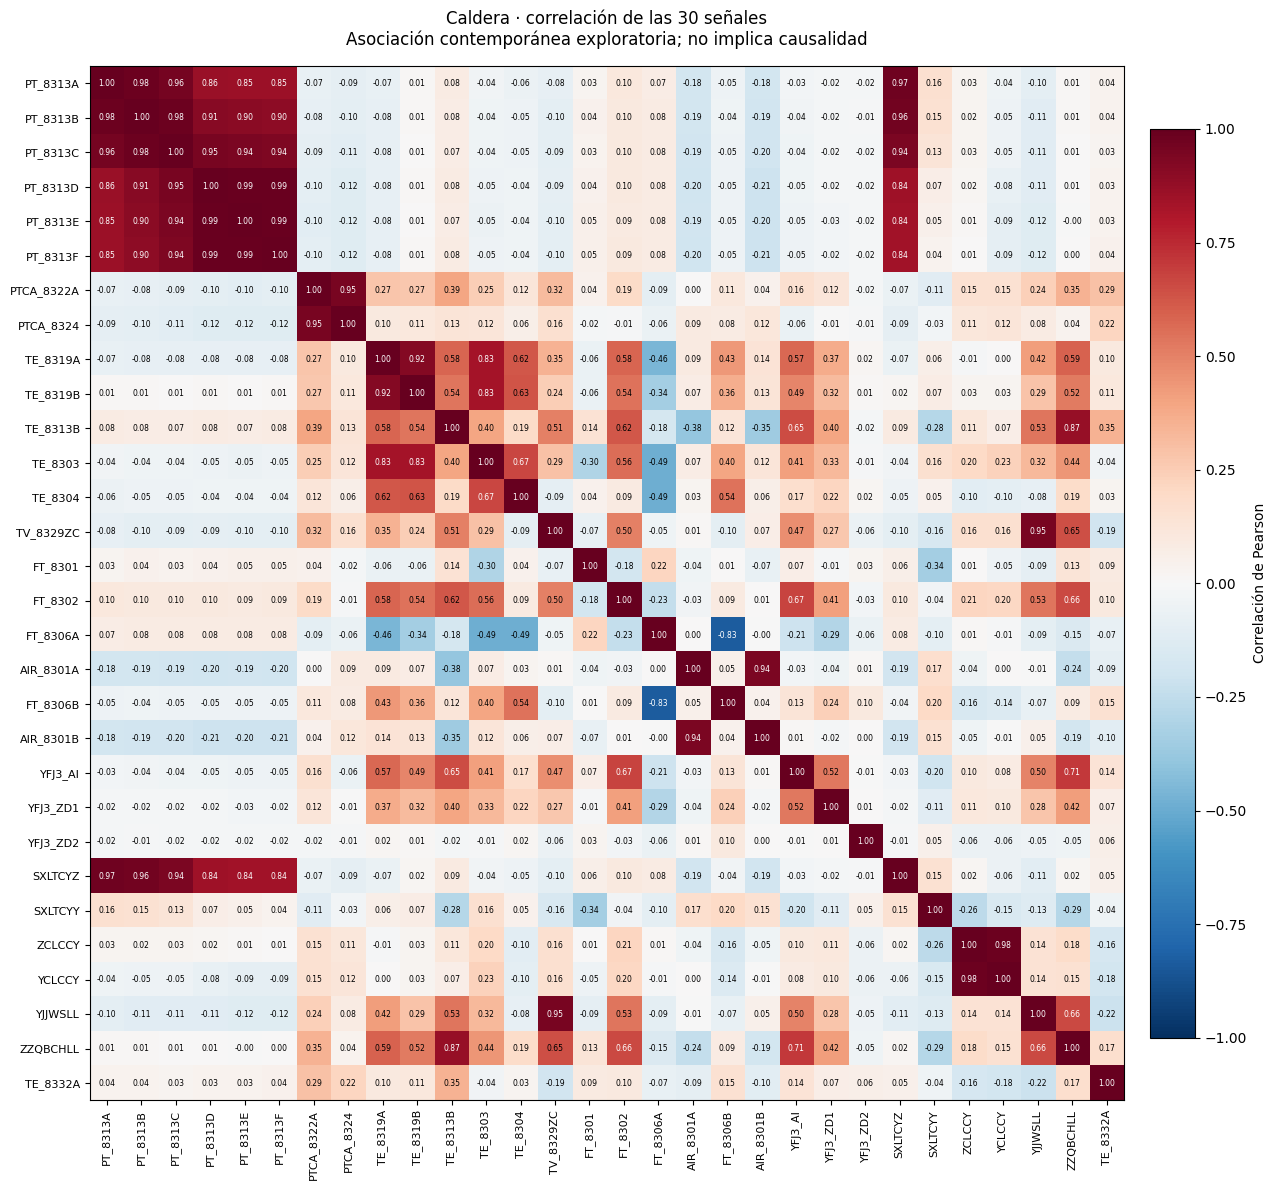

In [17]:
correlacion_spearman = valores.corr(method="spearman")
objetivo = "ZZQBCHLL.AV_0#"
predictoras = [sensor for sensor in sensores if sensor != objetivo]
asociacion_vapor = pd.DataFrame({
    "significado": [significado_es[sensor] for sensor in predictoras],
    "Pearson": correlaciones.loc[predictoras, objetivo],
    "Spearman": correlacion_spearman.loc[predictoras, objetivo],
    "pares_disponibles": [valores[[sensor, objetivo]].dropna().shape[0] for sensor in predictoras],
}).sort_values("Pearson", key=lambda columna: columna.abs(), ascending=False)
display(asociacion_vapor.round(4))

etiquetas = [sensor.removesuffix(".AV_0#") for sensor in sensores]
fig_correlacion, eje_correlacion = plt.subplots(figsize=(14, 12))
imagen_correlacion = eje_correlacion.imshow(correlaciones, cmap="RdBu_r", vmin=-1, vmax=1)
eje_correlacion.set_xticks(range(len(sensores)), etiquetas, rotation=90, fontsize=8)
eje_correlacion.set_yticks(range(len(sensores)), etiquetas, fontsize=8)
for fila in range(len(sensores)):
    for columna in range(len(sensores)):
        coeficiente = correlaciones.iloc[fila, columna]
        eje_correlacion.text(
            columna, fila, f"{coeficiente:.2f}", ha="center", va="center", fontsize=5.5,
            color="white" if abs(coeficiente) > 0.65 else "black",
        )
fig_correlacion.colorbar(imagen_correlacion, ax=eje_correlacion, fraction=0.035, pad=0.02, label="Correlación de Pearson")
eje_correlacion.set_title("Caldera · correlación de las 30 señales\nAsociación contemporánea exploratoria; no implica causalidad", pad=15)
fig_correlacion.tight_layout()
salida_correlacion = ruta.resolve().parents[2] / "outputs"
salida_correlacion.mkdir(exist_ok=True)
fig_correlacion.savefig(salida_correlacion / "serie2_matriz_correlacion.png", dpi=160, bbox_inches="tight")
plt.show()


**Cómo usar esta evidencia para seleccionar variables:** los pares con `|Pearson| >= 0.95` de la tabla anterior son candidatos a revisar redundancia, no exclusiones automáticas. Las señales corresponden a ubicaciones físicas diferentes y también pueden servir para detectar discrepancias entre sensores. Para el sensor virtual se comparará un conjunto completo con otro reducido por grupos físicos, considerando disponibilidad real de cada señal, calidad y rezagos. Para segmentar regímenes, la selección se revisará por separado, pues varias presiones muy correlacionadas pueden dar un peso excesivo a esa dimensión.

Un árbol de regresión o un bosque aleatorio puede asignar importancia, pero sí se entrena con un objetivo aunque solo se use para selección. Su importancia por reducción de impureza puede favorecer ciertas variables y repartir la importancia entre predictores correlacionados. Como apoyo posterior se propone medir cuánto empeora el error fuera del entrenamiento al retirar variables o grupos relacionados, con la misma validación temporal; si se usa permutación, la dependencia temporal y la correlación entre sensores requieren cautela, pues una permutación individual aleatoria puede producir combinaciones irreales y subestimar variables sustituibles. No se entrena un árbol adicional en este EDA ni se descartan sensores solo por este ranking.

Referencias metodológicas: [importancia por permutación, scikit-learn](https://scikit-learn.org/stable/modules/permutation_importance.html) y [efecto de predictores correlacionados](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html).


**Hallazgos observados:** frente al caudal de vapor, las mayores correlaciones absolutas de Pearson son temperatura alta del hogar `TE_8313B` (0.8686), corriente `YFJ3_AI` (0.7064), aire secundario `FT_8302` (0.6593), agua `YJJWSLL` (0.6591) y válvula `TV_8329ZC` (0.6463). Sus correlaciones Spearman son, respectivamente, 0.8441, 0.7711, 0.6008, 0.6356 y 0.6123. Estas señales merecen prioridad para estudiar el sensor virtual, sin constituir un conjunto final. Las seis presiones `PT_8313A`–`F` muestran asociaciones lineales contemporáneas con vapor entre -0.0008 y 0.0143, pese a su fuerte asociación mutua. Esto motiva comparar conjuntos reducidos en entrenamiento, sin eliminar esas presiones de la fuente ni de los análisis de regímenes o anomalías.


## Evolución de variables del proceso

La mediana por minuto permite ver tendencias de los cinco días sin llenar la gráfica con 86,400 puntos. Los datos originales siguen a cinco segundos; la reducción se usa solo para esta visualización.

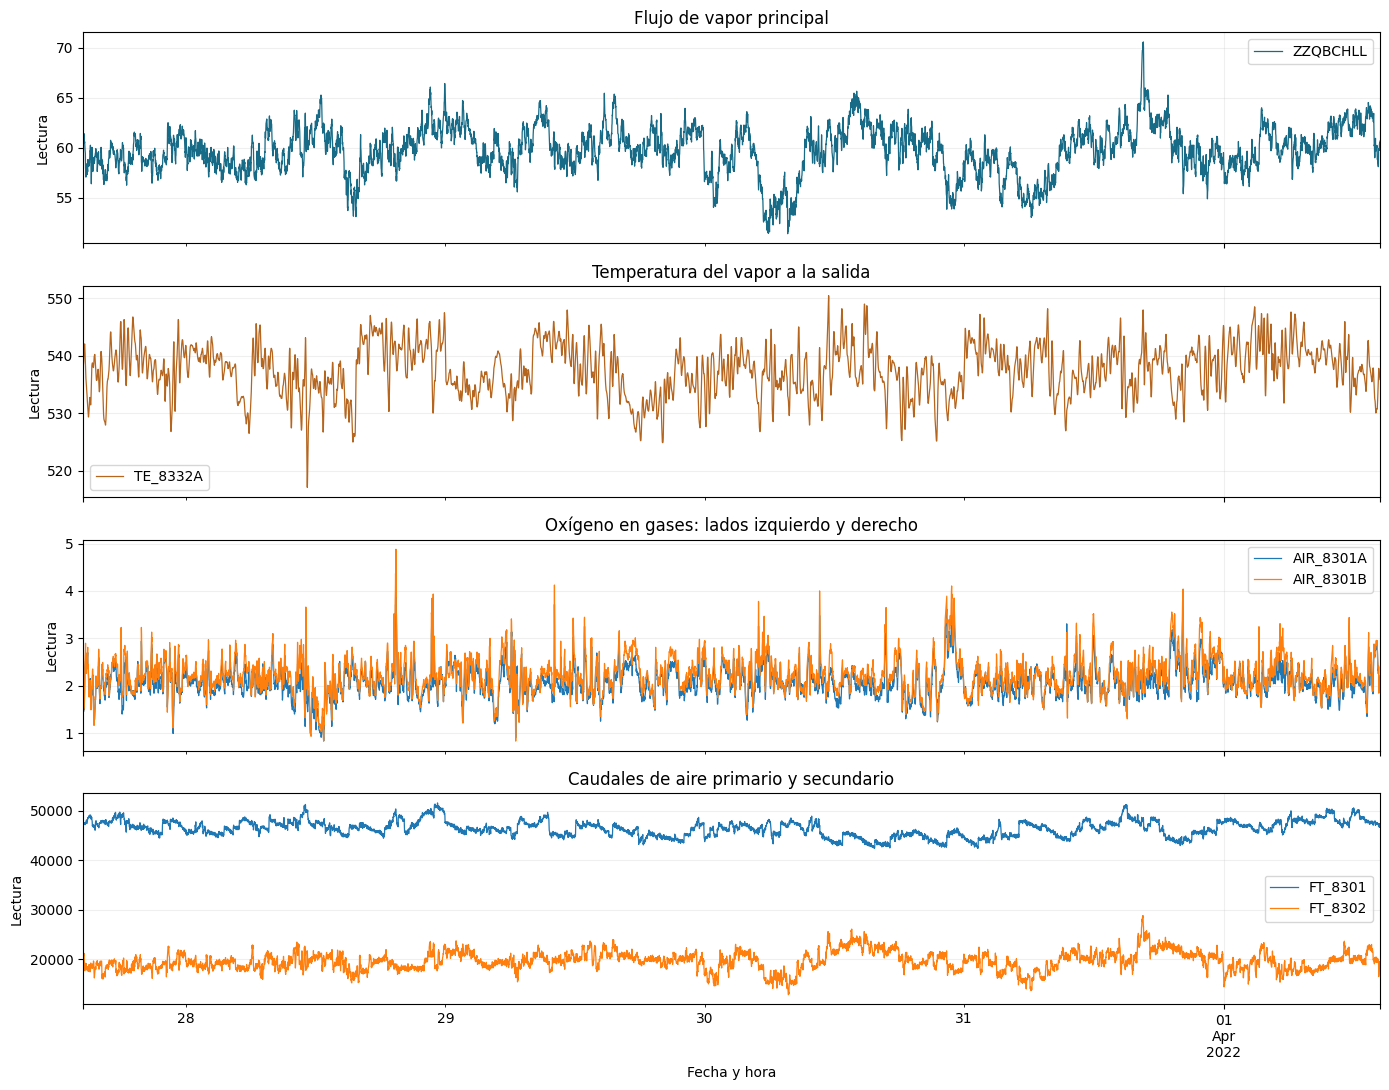

In [18]:
por_minuto = datos.set_index("date")[sensores].resample("1min").median()
fig, ejes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

por_minuto[["ZZQBCHLL.AV_0#"]].plot(ax=ejes[0], color="#176B87", linewidth=0.9)
ejes[0].set_title("Flujo de vapor principal")
ejes[0].set_ylabel("Lectura")
ejes[0].legend(["ZZQBCHLL"])

por_minuto[["TE_8332A.AV_0#"]].plot(ax=ejes[1], color="#B5651D", linewidth=0.9)
ejes[1].set_title("Temperatura del vapor a la salida")
ejes[1].set_ylabel("Lectura")
ejes[1].legend(["TE_8332A"])

por_minuto[["AIR_8301A.AV_0#", "AIR_8301B.AV_0#"]].plot(ax=ejes[2], linewidth=0.9)
ejes[2].set_title("Oxígeno en gases: lados izquierdo y derecho")
ejes[2].set_ylabel("Lectura")
ejes[2].legend(["AIR_8301A", "AIR_8301B"])

por_minuto[["FT_8301.AV_0#", "FT_8302.AV_0#"]].plot(ax=ejes[3], linewidth=0.9)
ejes[3].set_title("Caudales de aire primario y secundario")
ejes[3].set_ylabel("Lectura")
ejes[3].legend(["FT_8301", "FT_8302"])
ejes[3].set_xlabel("Fecha y hora")
for eje in ejes:
    eje.grid(alpha=0.2)
fig.tight_layout()

## Lectura inicial del EDA

- El archivo conserva 30 faltantes, todos en el caudal de agua de atemperación `YJJWSLL.AV_0#`; no hay fechas repetidas, filas repetidas ni vectores completos de sensores repetidos.
- El calendario mantiene intervalos regulares de cinco segundos y todas las señales tienen variación. Los tramos largos de valores idénticos y las correlaciones altas merecen revisión, pero no prueban que un sensor esté defectuoso.
- Tukey y MAD señalan observaciones alejadas de la distribución global. Aparecen candidatos simultáneos en varias señales, en especial en las presiones de la parte alta del hogar; se deben revisar como episodios conjuntos y contrastar con alarmas/estados antes de atribuirlos a sensores o al equipo.
- En las 86,400 filas, 6,817 (7.9 %) tienen al menos un candidato según MAD global `|z| > 3.5`. Este umbral no es etiqueta de falla: con cinco días de señal autocorrelacionada y cambios de carga puede marcar transiciones reales.
- El diccionario no da unidades ni límites normales; la documentación original revisada más abajo aporta un rango operativo para la temperatura de vapor. Por eso los valores negativos o magnitudes extremas no se declaran errores físicos solo por su signo o por los umbrales estadísticos.

Este EDA describe calidad y distribución. La identificación de regímenes, sensor virtual, anomalías y oportunidades de eficiencia queda para apartados posteriores de la Serie II.

## Investigación contextual: ¿hay mediciones demostrablemente incorrectas?

Se revisan los extremos de corriente, caudal de retorno y vibración, un episodio de presiones simultáneas y el tramo constante de la válvula. Se escogieron a partir del EDA, por lo que son casos de auditoría, no una muestra aleatoria ni un clasificador de todos los sensores.

### Contraste con la publicación original

Se descargaron las dos versiones de los autores y su código desde [Figshare, registro 28868849](https://doi.org/10.6084/m9.figshare.28868849.v1). Las descargas se contrastaron con los MD5 de Figshare y ambos CSV coinciden byte por byte con los de Kaggle. Los SHA-256 siguientes permiten repetir el contraste local. Esto comprueba fidelidad de la copia; no certifica cada lectura del sensor. Los archivos contrastados y sus URLs se conservan en `data/raw/serie2/fuente_autores/procedencia.json`, fuera de Git.

El [artículo original](https://pmc.ncbi.nlm.nih.gov/articles/PMC12052967/) sí identifica `TE_8332A` en °C y define 530–545 °C como rango normal de esa instalación. Su definición de anomalía es una salida de ese rango, no una etiqueta de sensor defectuoso. Para las otras señales no se localizaron unidades/rangos instrumentales ni un registro de fallas confirmadas. El código AutoReg de los autores se leyó sin ejecutarlo; emplea hasta 10,000 observaciones previas y 10 rezagos para completar los huecos.

In [19]:
import hashlib

hashes_autores = {
    "data.csv": "195b5e6e9b1b7c01613eb00f1f684e61aa237938239454dd7a00d86dd9cfdab0",
    "data_AutoReg.csv": "e4c6078775fc24a72e3c1be4bb36c36902a2d6c30c1358bcba409caadf072f84",
}
contraste_fuente = []
for archivo, hash_autor in hashes_autores.items():
    hash_local = hashlib.sha256((ruta / archivo).read_bytes()).hexdigest()
    contraste_fuente.append({
        "archivo": archivo,
        "sha256_local": hash_local,
        "coincide_con_original_de_autores": hash_local == hash_autor,
    })
contraste_fuente = pd.DataFrame(contraste_fuente)
assert contraste_fuente["coincide_con_original_de_autores"].all()
contraste_fuente

,archivo,sha256_local,coincide_con_original_de_autores
0,data.csv,195b5e6e9b1b7c01613eb00f1f684e61aa237938239454...,True
1,data_AutoReg.csv,e4c6078775fc24a72e3c1be4bb36c36902a2d6c30c1358...,True


In [20]:
temperatura = datos["TE_8332A.AV_0#"]
fuera_rango_fuente = temperatura.lt(530) | temperatura.gt(545)
resumen_temperatura_fuente = pd.DataFrame({
    "condición": ["Menor de 530 °C", "Entre 530 y 545 °C, incluidos", "Mayor de 545 °C"],
    "filas": [int(temperatura.lt(530).sum()), int(temperatura.between(530, 545).sum()), int(temperatura.gt(545).sum())],
})
resumen_temperatura_fuente["porcentaje"] = 100 * resumen_temperatura_fuente["filas"] / len(datos)
resumen_temperatura_fuente

,condición,filas,porcentaje
0,Menor de 530 °C,4144,4.796296
1,"Entre 530 y 545 °C, incluidos",79363,91.855324
2,Mayor de 545 °C,2893,3.348380


La aplicación literal del intervalo normal inclusivo da 7,037 registros fuera de rango (8.14 %), frente al 8.6 % descrito en la publicación. Si también se señalan los valores iguales a los límites, serían 7,073 (8.19 %); esa convención tampoco reproduce 8.6 %. Se conserva la discrepancia documental sin cambiar umbrales para forzar una coincidencia. Los registros fuera de rango siguen siendo mediciones observadas y se preservan para estudiar anomalías operativas.

### Lecturas retenidas cada dos registros

La repetición regular de valores merece distinguirse de un bloqueo accidental. Se examinan pares consecutivos desde el primer registro, sin escoger una fase por su mejor resultado. Una repetición exacta en todos los segundos elementos es compatible con actualización efectiva cada diez segundos o retención en la adquisición; el artículo no permite confirmar cuál mecanismo la produjo.

In [21]:
retencion_por_pares = []
for sensor in sensores:
    s = datos[sensor].reset_index(drop=True)
    igualdad = s.eq(s.shift())
    retencion_por_pares.append({
        "sensor": sensor,
        "segundos_elementos_iguales": int(igualdad.iloc[1::2].sum()),
        "pares_examinados": len(igualdad.iloc[1::2]),
        "cambios_en_primeros_elementos_posteriores": int((~igualdad.iloc[2::2]).sum()),
    })
retencion_por_pares = pd.DataFrame(retencion_por_pares)
retencion_regular = retencion_por_pares.loc[
    retencion_por_pares["segundos_elementos_iguales"].eq(retencion_por_pares["pares_examinados"])
]
retencion_regular

,sensor,segundos_elementos_iguales,pares_examinados,cambios_en_primeros_elementos_posteriores
23,SXLTCYZ.AV_0#,43200,43200,43061
24,SXLTCYY.AV_0#,43200,43200,43080
25,ZCLCCY.AV_0#,43200,43200,43186
26,YCLCCY.AV_0#,43200,43200,43187
28,ZZQBCHLL.AV_0#,43200,43200,42517


Los cinco tags de la tabla repiten exactamente su lectura en los 43,200 pares. Incluyen el objetivo de vapor y cuatro presiones diferenciales. La cadencia de filas sigue siendo cinco segundos, pero estos segundos registros no aportan una medición nueva para esas señales. Se conservan los instantes, y este patrón debe tenerse presente al elegir rezagos y validar el sensor virtual.

### Contexto de los extremos seleccionados

Se muestran valores antes y después, y la mediana de los cinco minutos anteriores. Se exploran también dos minutos posteriores para contemplar respuestas con retardo. Esta inspección es retrospectiva: los datos posteriores no se usarán como entradas de un modelo destinado a funcionar en tiempo real.

In [22]:
serie = datos.set_index("date")
casos_contexto = [
    ("Corriente máxima", "2022-03-29 14:06:59", ["YFJ3_AI.AV_0#", "YFJ3_ZD1.AV_0#", "YFJ3_ZD2.AV_0#", "ZZQBCHLL.AV_0#"]),
    ("Caudal de retorno mínimo", "2022-03-30 08:53:09", ["FT_8306A.AV_0#", "FT_8306B.AV_0#", "PT_8313A.AV_0#", "ZZQBCHLL.AV_0#"]),
    ("Presiones extremas", "2022-03-28 14:08:09", ["PT_8313A.AV_0#", "PT_8313B.AV_0#", "PT_8313C.AV_0#", "PT_8313D.AV_0#", "PT_8313E.AV_0#", "PT_8313F.AV_0#", "SXLTCYZ.AV_0#"]),
    ("Vibración B máxima", "2022-03-30 07:47:09", ["YFJ3_ZD2.AV_0#", "YFJ3_ZD1.AV_0#", "YFJ3_AI.AV_0#", "FT_8302.AV_0#"]),
]
filas_contexto = []
for caso, instante, columnas in casos_contexto:
    instante = pd.Timestamp(instante)
    previo = serie.loc[instante - pd.Timedelta(minutes=5):instante - pd.Timedelta(seconds=5), columnas]
    posterior = serie.loc[instante:instante + pd.Timedelta(minutes=2), columnas]
    for sensor in columnas:
        filas_contexto.append({
            "caso": caso,
            "instante": instante,
            "sensor": sensor,
            "mediana_previa_5min": previo[sensor].median(),
            "cinco_segundos_antes": serie.loc[instante - pd.Timedelta(seconds=5), sensor],
            "lectura_en_evento": serie.loc[instante, sensor],
            "cinco_segundos_después": serie.loc[instante + pd.Timedelta(seconds=5), sensor],
            "mínimo_hasta_2min_después": posterior[sensor].min(),
            "máximo_hasta_2min_después": posterior[sensor].max(),
        })
contexto_extremos = pd.DataFrame(filas_contexto)
contexto_extremos.round(3)

C:\Users\user\AppData\Local\Temp\ipykernel_4832\3790490866.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  contexto_extremos.round(3)


,caso,instante,sensor,mediana_previa_5min,cinco_segundos_antes,lectura_en_evento,cinco_segundos_después,mínimo_hasta_2min_después,máximo_hasta_2min_después
0,Corriente máxima,2022-03-29 14:06:59,YFJ3_AI.AV_0#,22.070,22.36,51.28,18.42,18.42,51.28
1,Corriente máxima,2022-03-29 14:06:59,YFJ3_ZD1.AV_0#,5.565,5.73,8.26,2.90,2.90,8.26
2,Corriente máxima,2022-03-29 14:06:59,YFJ3_ZD2.AV_0#,5.670,6.27,11.89,7.23,3.74,11.89
3,Corriente máxima,2022-03-29 14:06:59,ZZQBCHLL.AV_0#,57.565,56.18,56.18,55.89,55.89,58.30
4,Caudal de retorno mínimo,2022-03-30 08:53:09,FT_8306A.AV_0#,720.920,420.70,262.49,641.66,262.49,687.53
5,Caudal de retorno mínimo,2022-03-30 08:53:09,FT_8306B.AV_0#,601.580,327.82,304.96,650.95,304.96,667.37
6,Caudal de retorno mínimo,2022-03-30 08:53:09,PT_8313A.AV_0#,-161.755,-129.61,-132.55,-123.40,-132.55,-62.72
7,Caudal de retorno mínimo,2022-03-30 08:53:09,ZZQBCHLL.AV_0#,56.470,56.31,56.31,56.41,56.31,57.17
8,Presiones extremas,2022-03-28 14:08:09,PT_8313A.AV_0#,-222.725,-458.34,-449.61,-452.97,-484.70,-235.69
9,Presiones extremas,2022-03-28 14:08:09,PT_8313B.AV_0#,-277.195,-518.68,-530.18,-526.49,-545.71,-269.18


Los extremos positivos de presión también se contrastan entre los seis puntos. Sus máximos se concentran en dos instantes compartidos; esto aporta evidencia de un episodio común, pero no distingue por sí mismo un fenómeno físico de una interferencia compartida.

In [23]:
presiones_hogar = [f"PT_8313{letra}.AV_0#" for letra in "ABCDEF"]
instantes_maximos = sorted(set(serie[presiones_hogar].idxmax()))
maximos_presion_compartidos = serie.loc[instantes_maximos, presiones_hogar]
maximos_presion_compartidos

,PT_8313A.AV_0#,PT_8313B.AV_0#,PT_8313C.AV_0#,PT_8313D.AV_0#,PT_8313E.AV_0#,PT_8313F.AV_0#
date,,,,,,
2022-03-28 06:35:09,69.79,44.11,126.28,256.53,245.11,174.87
2022-03-31 22:44:14,75.33,51.83,123.25,194.34,168.91,122.67


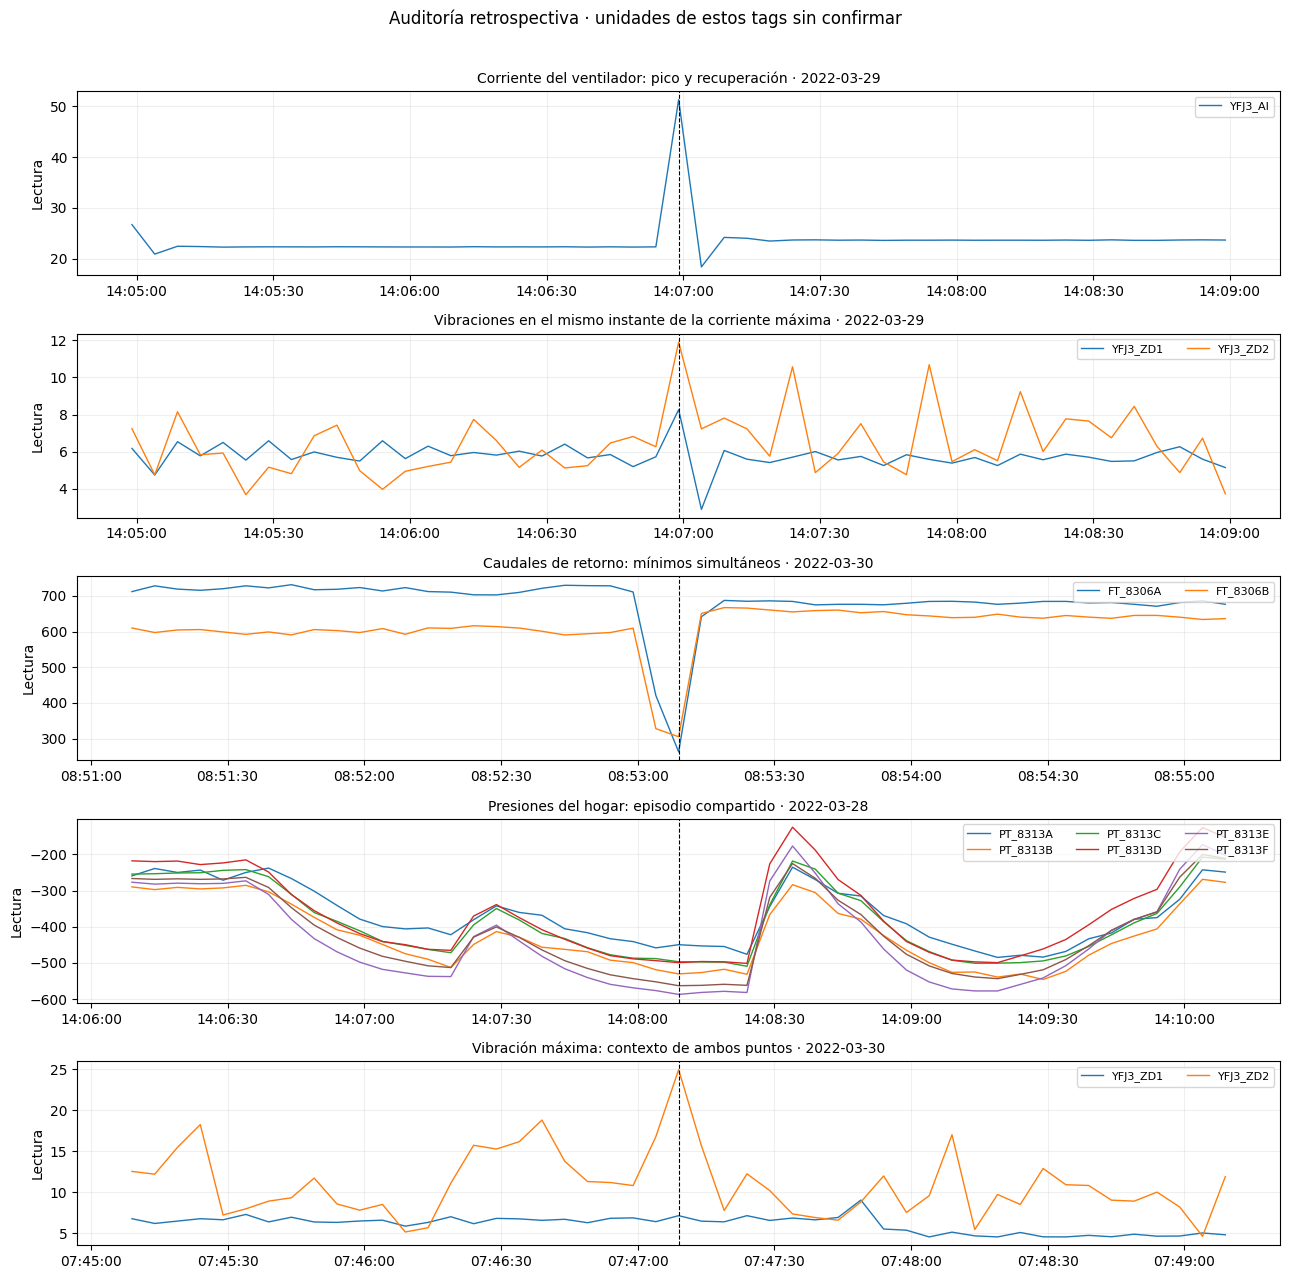

In [24]:
import matplotlib.dates as mdates

paneles = [
    ("2022-03-29 14:06:59", ["YFJ3_AI.AV_0#"], "Corriente del ventilador: pico y recuperación"),
    ("2022-03-29 14:06:59", ["YFJ3_ZD1.AV_0#", "YFJ3_ZD2.AV_0#"], "Vibraciones en el mismo instante de la corriente máxima"),
    ("2022-03-30 08:53:09", ["FT_8306A.AV_0#", "FT_8306B.AV_0#"], "Caudales de retorno: mínimos simultáneos"),
    ("2022-03-28 14:08:09", [f"PT_8313{letra}.AV_0#" for letra in "ABCDEF"], "Presiones del hogar: episodio compartido"),
    ("2022-03-30 07:47:09", ["YFJ3_ZD1.AV_0#", "YFJ3_ZD2.AV_0#"], "Vibración máxima: contexto de ambos puntos"),
]
fig_contexto, ejes = plt.subplots(len(paneles), 1, figsize=(13, 13))
for eje, (instante, columnas, titulo) in zip(ejes, paneles):
    instante = pd.Timestamp(instante)
    ventana = serie.loc[instante - pd.Timedelta(minutes=2):instante + pd.Timedelta(minutes=2), columnas]
    for sensor in columnas:
        eje.plot(ventana.index, ventana[sensor], label=sensor.split(".")[0], linewidth=1)
    eje.axvline(instante, color="black", linestyle="--", linewidth=0.8)
    eje.set_title(f"{titulo} · {instante.date()}", fontsize=10)
    eje.set_ylabel("Lectura")
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    eje.legend(loc="upper right", fontsize=8, ncol=min(len(columnas), 3))
    eje.grid(alpha=0.2)
fig_contexto.suptitle("Auditoría retrospectiva · unidades de estos tags sin confirmar", fontsize=12)
fig_contexto.tight_layout(rect=[0, 0, 1, 0.97])
carpeta_figuras = ruta.resolve().parents[2] / "outputs"
carpeta_figuras.mkdir(exist_ok=True)
fig_contexto.savefig(carpeta_figuras / "serie2_contexto_extremos.png", dpi=130, bbox_inches="tight")

In [25]:
inicio_valvula = pd.Timestamp("2022-03-29 03:50:54")
fin_valvula = pd.Timestamp("2022-03-29 04:54:29")
tramo_valvula = serie.loc[inicio_valvula:fin_valvula, ["TV_8329ZC.AV_0#", "YJJWSLL.AV_0#", "TE_8332A.AV_0#", "ZZQBCHLL.AV_0#"]]
resumen_tramo_valvula = tramo_valvula.agg(["min", "max", "nunique"]).T
resumen_tramo_valvula.rename(columns={"min": "mínimo", "max": "máximo", "nunique": "lecturas_distintas"})

,mínimo,máximo,lecturas_distintas
TV_8329ZC.AV_0#,11.61,11.61,1.0
YJJWSLL.AV_0#,2.54,2.65,12.0
TE_8332A.AV_0#,532.66,540.86,294.0
ZZQBCHLL.AV_0#,56.83,62.30,254.0


### Qué permiten concluir estos contrastes

| Caso | Evidencia observada | Interpretación y tratamiento |
|---|---|---|
| Corriente máxima | 22.36 → 51.28 → 18.42. En el mismo instante, vibración A sube 5.73 → 8.26 y B 6.27 → 11.89. | Hay un pico compartido con otras señales; no es una lectura aislada sin acompañamiento. Un evento electromecánico y una interferencia común siguen siendo explicaciones posibles. Conservar y señalar. |
| Presiones extremas, negativas y positivas | Los seis puntos de presión del hogar y un diferencial se desplazan juntos durante varios registros. Los máximos positivos también coinciden entre los seis puntos en dos instantes. | Hay coherencia temporal y espacial. No se identifica un único sensor incorrecto; conservar como episodio conjunto, sin afirmar que su causa física esté demostrada. |
| Caudales de retorno | A y B caen simultáneamente durante dos registros y se recuperan. | Puede ser un transitorio común o un problema compartido de adquisición; la simultaneidad no decide cuál. Conservar con revisión. |
| Vibración B máxima | 16.80 → 24.96 → 15.69; la mediana de los cinco minutos previos ya era 11.27 frente a mediana global 6.35. | Existe contexto local elevado y un pico. La corriente cambia poco en ese instante; eso no descarta una vibración mecánica localizada. Conservar con revisión. |
| Válvula constante | 764 registros en 11.61. En ese tramo cambian el agua (2.54–2.65), la temperatura (532.66–540.86 °C) y el vapor (56.83–62.30). | No se congeló todo el registro. Una orden sostenida es plausible, pero falta saber si el tag mide orden o posición real. No invalidar ni imputar automáticamente. |

No se encontró una lectura numérica que pueda declararse imposible con los rangos instrumentales actualmente documentados. Esto no demuestra que todas sean correctas: faltan calibraciones, calidad de señal, alarmas, acciones de control y registros de mantenimiento. Los 30 faltantes sí son ausencias comprobadas; se preservan sin asignarles causa.

La decisión es conservar los valores y separar las banderas de revisión de cualquier exclusión. Una futura sensibilidad del entrenamiento puede evaluar el efecto de los casos sospechosos, manteniendo los eventos para el análisis de anomalías. No se elimina ningún registro ni se rellena ninguna medición en esta auditoría.

## Revisión específica de la señal de válvula constante

El tramo exacto de 63.58 minutos se examina contra el patrón habitual de esta misma señal, sus límites y las variables asociadas. No se interpreta la etiqueta TV como posición real confirmada: el diccionario solo la describe como válvula reguladora de temperatura del atemperador primario.

### ¿Es un tramo excepcional?

Se calculan todos los tramos de lectura idéntica. Para describir el tamaño de los cambios, se redondean las diferencias a los dos decimales presentes en el archivo; no se introduce una tolerancia de ingeniería.

In [26]:
senal_valvula = serie["TV_8329ZC.AV_0#"]
base_tramos = senal_valvula.rename("valor").reset_index()
base_tramos["grupo"] = base_tramos["valor"].ne(base_tramos["valor"].shift()).cumsum()
tramos_valvula = base_tramos.groupby("grupo", sort=False).agg(
    inicio=("date", "first"), fin=("date", "last"),
    muestras=("valor", "size"), valor=("valor", "first"),
)
tramos_valvula["minutos_transcurridos"] = (tramos_valvula["fin"] - tramos_valvula["inicio"]).dt.total_seconds() / 60
tramos_largos_valvula = tramos_valvula.loc[tramos_valvula["minutos_transcurridos"].ge(30)]
cambios_valvula = senal_valvula.diff().abs().round(2).dropna()
cambios_valvula = cambios_valvula.loc[cambios_valvula.gt(0)]
resumen_patron_valvula = pd.DataFrame({
    "medida": ["Tramos idénticos", "Tramos de al menos 30 minutos", "Porcentaje de registros en esos tramos", "Cambios de valor", "Porcentaje de cambios de 0.01"],
    "resultado": [len(tramos_valvula), len(tramos_largos_valvula),
        100 * tramos_largos_valvula["muestras"].sum() / len(serie),
        len(cambios_valvula), 100 * cambios_valvula.eq(0.01).mean()],
})
resumen_patron_valvula.round(3)

,medida,resultado
0,Tramos idénticos,10674.000
1,Tramos de al menos 30 minutos,16.000
2,Porcentaje de registros en esos tramos,9.602
3,Cambios de valor,10673.000
4,Porcentaje de cambios de 0.01,91.952


In [27]:
tramos_largos_valvula.sort_values("muestras", ascending=False).reset_index(drop=True).round(3)

C:\Users\user\AppData\Local\Temp\ipykernel_4832\2184919031.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  tramos_largos_valvula.sort_values("muestras", ascending=False).reset_index(drop=True).round(3)


,inicio,fin,muestras,valor,minutos_transcurridos
0,2022-03-29 03:50:54,2022-03-29 04:54:29,764,11.61,63.583
1,2022-03-30 20:29:24,2022-03-30 21:27:09,694,20.56,57.750
2,2022-03-28 04:49:54,2022-03-28 05:43:59,650,15.04,54.083
3,2022-03-31 18:45:44,2022-03-31 19:39:34,647,22.52,53.833
4,2022-04-01 06:32:04,2022-04-01 07:24:04,625,11.62,52.000
5,2022-03-30 11:54:39,2022-03-30 12:37:19,513,18.62,42.667
6,2022-03-31 10:46:29,2022-03-31 11:28:39,507,16.54,42.167
7,2022-04-01 12:15:59,2022-04-01 12:56:09,483,18.97,40.167
8,2022-03-30 00:24:44,2022-03-30 01:03:19,464,13.05,38.583
9,2022-03-31 15:53:34,2022-03-31 16:30:49,448,20.02,37.250


### Sensibilidad a la igualdad exacta

Se amplía el intervalo identificado mientras la lectura siga entre 11.60 y 11.62: un centésimo a cada lado de 11.61. Es una sensibilidad a la precisión del registro, no un criterio para declarar que la válvula opera correctamente.

In [28]:
izquierda = serie.index.get_loc(inicio_valvula)
derecha = serie.index.get_loc(fin_valvula)
cerca_del_nivel = senal_valvula.between(11.60, 11.62).to_numpy()
while izquierda > 0 and cerca_del_nivel[izquierda - 1]:
    izquierda -= 1
while derecha + 1 < len(serie) and cerca_del_nivel[derecha + 1]:
    derecha += 1
inicio_casi_constante = serie.index[izquierda]
fin_casi_constante = serie.index[derecha]
comparacion_tramos = []
for criterio, inicio, fin in [
    ("Igual a 11.61", inicio_valvula, fin_valvula),
    ("Entre 11.60 y 11.62", inicio_casi_constante, fin_casi_constante),
]:
    bloque = serie.loc[inicio:fin]
    comparacion_tramos.append({
        "criterio": criterio, "inicio": inicio, "fin": fin,
        "muestras": len(bloque), "minutos_transcurridos": (fin - inicio).total_seconds() / 60,
        "agua_mínima": bloque["YJJWSLL.AV_0#"].min(),
        "agua_máxima": bloque["YJJWSLL.AV_0#"].max(),
        "temperatura_mínima_C": bloque["TE_8332A.AV_0#"].min(),
        "temperatura_máxima_C": bloque["TE_8332A.AV_0#"].max(),
        "registros_fuera_banda_térmica_fuente": int((~bloque["TE_8332A.AV_0#"].between(530, 545)).sum()),
    })
comparacion_tramos = pd.DataFrame(comparacion_tramos)
comparacion_tramos.round(3)

C:\Users\user\AppData\Local\Temp\ipykernel_4832\2553947224.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  comparacion_tramos.round(3)


,criterio,inicio,fin,muestras,minutos_transcurridos,agua_mínima,agua_máxima,temperatura_mínima_C,temperatura_máxima_C,registros_fuera_banda_térmica_fuente
0,Igual a 11.61,2022-03-29 03:50:54,2022-03-29 04:54:29,764,63.583,2.54,2.65,532.66,540.86,0
1,Entre 11.60 y 11.62,2022-03-29 03:05:29,2022-03-29 06:51:59,2719,226.500,2.54,2.71,528.58,540.86,59


In [29]:
puntos_limite = []
for evento, instante, horizontes in [
    ("Inicio del tramo exacto", inicio_valvula, [-5, 0]),
    ("Fin del tramo exacto", fin_valvula + pd.Timedelta(seconds=5), [-5, 0]),
    ("Entrada al nivel estable", inicio_casi_constante, [-5, 0, 10, 30, 60]),
    ("Salida del nivel estable", fin_casi_constante + pd.Timedelta(seconds=5), [-5, 0, 10, 30, 60]),
]:
    for segundos in horizontes:
        fecha = instante + pd.Timedelta(seconds=segundos)
        puntos_limite.append({
            "evento": evento, "segundos_desde_cambio": segundos, "fecha": fecha,
            "válvula": serie.loc[fecha, "TV_8329ZC.AV_0#"],
            "agua": serie.loc[fecha, "YJJWSLL.AV_0#"],
            "temperatura_salida_C": serie.loc[fecha, "TE_8332A.AV_0#"],
        })
contexto_cambios_nivel = pd.DataFrame(puntos_limite)
contexto_cambios_nivel

,evento,segundos_desde_cambio,fecha,válvula,agua,temperatura_salida_C
0,Inicio del tramo exacto,-5,2022-03-29 03:50:49,11.60,2.55,536.81
1,Inicio del tramo exacto,0,2022-03-29 03:50:54,11.61,2.55,536.81
2,Fin del tramo exacto,-5,2022-03-29 04:54:29,11.61,2.59,540.53
3,Fin del tramo exacto,0,2022-03-29 04:54:34,11.62,2.60,540.53
4,Entrada al nivel estable,-5,2022-03-29 03:05:24,13.03,2.68,533.54
5,Entrada al nivel estable,0,2022-03-29 03:05:29,11.61,2.68,533.53
6,Entrada al nivel estable,10,2022-03-29 03:05:39,11.61,2.65,533.60
7,Entrada al nivel estable,30,2022-03-29 03:05:59,11.61,2.58,533.63
8,Entrada al nivel estable,60,2022-03-29 03:06:29,11.61,2.56,533.69
9,Salida del nivel estable,-5,2022-03-29 06:51:59,11.62,2.63,539.30


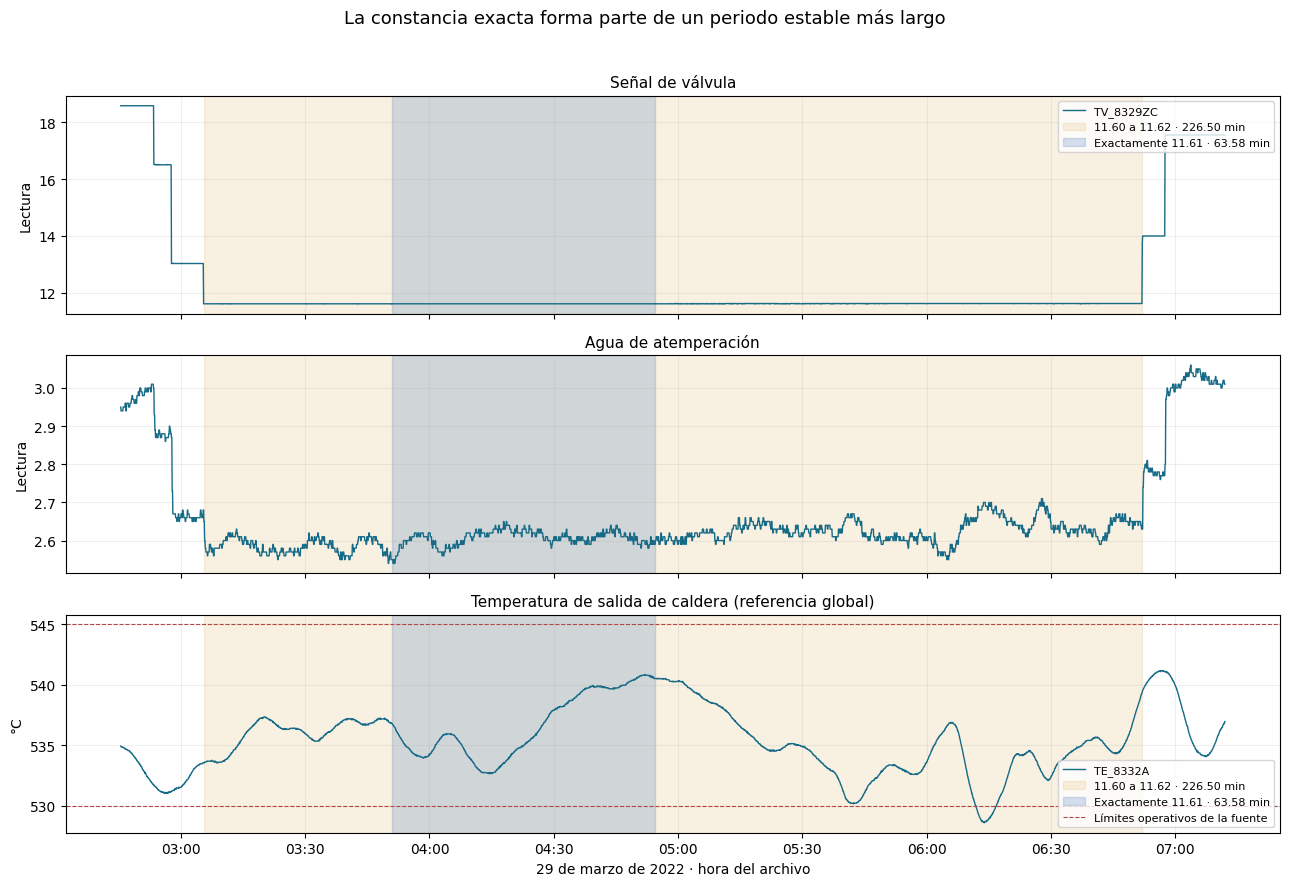

In [30]:
ventana_valvula = serie.loc[
    inicio_casi_constante - pd.Timedelta(minutes=20):fin_casi_constante + pd.Timedelta(minutes=20)
]
fig_valvula, ejes_valvula = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for eje, sensor, titulo, unidad in zip(
    ejes_valvula,
    ["TV_8329ZC.AV_0#", "YJJWSLL.AV_0#", "TE_8332A.AV_0#"],
    ["Señal de válvula", "Agua de atemperación", "Temperatura de salida de caldera (referencia global)"],
    ["Lectura", "Lectura", "°C"],
):
    eje.plot(ventana_valvula.index, ventana_valvula[sensor], color="#176B87", linewidth=1, label=sensor.split(".")[0])
    eje.axvspan(inicio_casi_constante, fin_casi_constante, color="#D9A441", alpha=0.16, label="11.60 a 11.62 · 226.50 min")
    eje.axvspan(inicio_valvula, fin_valvula, color="#4676BD", alpha=0.22, label="Exactamente 11.61 · 63.58 min")
    eje.set_title(titulo, fontsize=11)
    eje.set_ylabel(unidad)
    eje.grid(alpha=0.2)
ejes_valvula[0].legend(loc="upper right", fontsize=8)
ejes_valvula[2].axhline(530, color="#B44646", linestyle="--", linewidth=0.8, label="Límites operativos de la fuente")
ejes_valvula[2].axhline(545, color="#B44646", linestyle="--", linewidth=0.8)
ejes_valvula[2].legend(loc="lower right", fontsize=8)
ejes_valvula[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ejes_valvula[2].set_xlabel("29 de marzo de 2022 · hora del archivo")
fig_valvula.suptitle("La constancia exacta forma parte de un periodo estable más largo", fontsize=13)
fig_valvula.tight_layout(rect=[0, 0, 1, 0.96])
fig_valvula.savefig(carpeta_figuras / "serie2_valvula_constante.png", dpi=130, bbox_inches="tight")

### Conclusión de tratamiento del tramo

La duración exacta de 63.58 minutos depende de cambios de un centésimo: empieza con 11.60 → 11.61 y termina con 11.61 → 11.62. Ampliando solo un centésimo a cada lado se obtiene un periodo de 226.5 minutos (03:05:29–06:51:59). Hay 16 tramos exactos de al menos media hora en el historial, a valores distintos; el 91.95 % de los cambios de esta señal son de 0.01. Por tanto, la constancia no es un evento excepcional que permita declarar un bloqueo o un dato incorrecto.

Durante el tramo exacto el agua oscila entre 2.54 y 2.65, y la temperatura de salida entre 532.66 y 540.86 °C: el registro no se congeló en conjunto y la temperatura permaneció dentro de la referencia de los autores. En el periodo ampliado hay 59 observaciones menores de 530 °C; tampoco se concluye que una señal estable equivalga siempre a operación normal. TE_8332A es temperatura global de salida, no una medida confirmada del punto regulado por esta válvula.

En los límites del periodo amplio se observa una respuesta concordante: al bajar la señal de 13.03 a 11.61, el agua pasa de 2.68 a 2.56 en 60 segundos; al subir de 11.62 a 14.00, pasa de 2.63 a 2.79. Esto apoya coherencia interna con retardo corto, sin confirmar causalidad ni que ambos tags sean mediciones independientes.

La interpretación más defendible es una señal mantenida por tramos, compatible con una orden o posición estable y con la precisión del registro. Una falla individual de medición, retención de adquisición o válvula atascada sigue sin poder excluirse. **Se conserva el tramo sin imputar ni eliminar; la duración aislada no justifica clasificarlo como error.**

Para diagnosticar una válvula atascada harían falta, como mínimo, demanda de apertura, posición real independiente, modo automático/manual y calidad de señal. [Emerson distingue consigna, recorrido y presiones en sus diagnósticos](https://www.emerson.com/en/final-control/catalog/products-and-software/valve-software/control-valve-diagnostics). Que el caudal varíe ligeramente con una señal estable tampoco prueba un error: el flujo depende de la posición y de la diferencia de presión. El [manual de válvulas de Fisher, sección 5.4](https://www.emerson.com/is/content/emerson/en/final-control/flow-controls/documents/d101881x012.pdf) distingue esa relación instalada. Aquí no están identificadas las presiones a ambos lados de esta válvula para verificarla cuantitativamente.

### Variabilidad de la señal de válvula y peso del periodo estable

Se compara la dispersión global con cinco bloques consecutivos de 24 horas de igual tamaño, contados desde el primer registro. Se emplea desviación estándar muestral (`ddof=1`), en unidades de la señal, pues no se ha confirmado su unidad física. Los porcentajes se calculan sobre filas; el periodo ampliado contiene el exacto y no se deben sumar.


In [31]:
senal = datos.set_index("date")["TV_8329ZC.AV_0#"]
mascara_exacta = senal.index.to_series().between(inicio_valvula, fin_valvula).to_numpy()
mascara_ampliada = senal.index.to_series().between(inicio_casi_constante, fin_casi_constante).to_numpy()
grupos = {
    "Total": senal,
    "Constancia exacta (63.58 min)": senal[mascara_exacta],
    "Periodo ampliado (226.5 min)": senal[mascara_ampliada],
    "Fuera del periodo ampliado": senal[~mascara_ampliada],
}
variabilidad_valvula = pd.DataFrame({
    nombre: {
        "filas": len(valores_tramo),
        "porcentaje_total": 100 * len(valores_tramo) / len(senal),
        "media": valores_tramo.mean(),
        "desviacion_estandar": valores_tramo.std(),
        "minimo": valores_tramo.min(),
        "maximo": valores_tramo.max(),
        "valores_distintos": valores_tramo.nunique(),
    }
    for nombre, valores_tramo in grupos.items()
}).T
display(variabilidad_valvula)

# Cada bloque contiene 17,280 observaciones consecutivas de cinco segundos.
bloques = pd.DataFrame({"fecha": senal.index, "valor": senal.to_numpy()})
bloques["bloque"] = bloques.index // 17280 + 1
variabilidad_por_bloque = bloques.groupby("bloque").agg(
    inicio=("fecha", "min"), fin=("fecha", "max"), filas=("valor", "size"),
    media=("valor", "mean"), desviacion_estandar=("valor", "std"),
    minimo=("valor", "min"), maximo=("valor", "max"),
    valores_distintos=("valor", "nunique"),
)
display(variabilidad_por_bloque)
frecuencia_moda = 100 * senal.value_counts().iloc[0] / len(senal)
print(f"El valor más frecuente reúne {frecuencia_moda:.2f}% de las filas.")


,filas,porcentaje_total,media,desviacion_estandar,minimo,maximo,valores_distintos
Total,86400.0,100.000000,16.082346,4.857964,1.64,35.48,366.0
Constancia exacta (63.58 min),764.0,0.884259,11.610000,0.000000,11.61,11.61,1.0
Periodo ampliado (226.5 min),2719.0,3.146991,11.613961,0.004944,11.60,11.62,3.0
Fuera del periodo ampliado,83681.0,96.853009,16.227535,4.867935,1.64,35.48,365.0


,inicio,fin,filas,media,desviacion_estandar,minimo,maximo,valores_distintos
bloque,,,,,,,,
1,2022-03-27 14:28:54,2022-03-28 14:28:49,17280,16.814321,4.094575,3.17,33.99,129
2,2022-03-28 14:28:54,2022-03-29 14:28:49,17280,14.956177,4.492473,3.19,32.05,131
3,2022-03-29 14:28:54,2022-03-30 14:28:49,17280,17.646784,5.753089,1.64,35.48,154
4,2022-03-30 14:28:54,2022-03-31 14:28:49,17280,15.229848,4.594176,4.15,29.03,132
5,2022-03-31 14:28:54,2022-04-01 14:28:49,17280,15.764603,4.666123,4.14,35.20,149


El valor más frecuente reúne 3.46% de las filas.


**Interpretación:** la señal no es casi constante globalmente: presenta 366 valores, desviación estándar 4.858 y rango 1.64–35.48. En cada bloque de 24 horas la desviación está entre 4.095 y 5.753. El tramo exacto representa 0.884 % de las filas y el ampliado, que lo contiene, 3.147 %; fuera de este último la desviación es 4.868. La constancia local no justifica eliminar la columna ni sus filas. Tampoco basta que un episodio sea pequeño para descartarlo: debe evaluarse su validez y significado. Se conserva la señal. La dispersión demuestra variación, pero no prueba aporte predictivo adicional; eso requerirá comparar el sensor virtual con y sin esta variable bajo la misma validación temporal.
